# Bước 0. Hiểu tình hình kinh doanh (Business Understanding)

Notebook này vẽ bức tranh kinh doanh bằng số thật, trước khi đi vào phân tích từng shop. Mỗi phần đi theo thứ tự: nói trước sẽ xem gì, chạy câu lệnh, rồi đọc kết quả.

**Cách chạy:**
- Đặt notebook cùng thư mục với `clean_data/` (dữ liệu sạch do `BI10_R03_clean.ipynb` tạo ra) và file `r3_db.py`.
- Cài thư viện: `pip install duckdb pandas matplotlib`.
- Chạy từ trên xuống. Lần đầu, ô mở dữ liệu sẽ nạp các file CSV sạch vào file `output/r3_clean.duckdb` (mất vài phút). Các notebook Bước 1 đến Bước 4 dùng chung file này nên các lần sau mở rất nhanh.

**Cách tính dùng chung trong notebook:**
- Một contract (hợp đồng) được tính là đã ký khi cột `is_signed` bằng 1, tức `name_status` là Active, Finished, Paid off, Written off hoặc Signed.
- Hồ sơ và contract được xếp vào tháng khách nộp hồ sơ (`apply_month`).
- "Shop" là các điểm bán có trong bảng salesroom.

Ô dưới đây mở dữ liệu sạch, tạo hàm `q()` để chạy một câu SQL và trả kết quả ra dạng bảng, và đặt kiểu biểu đồ dùng chung.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from r3_db import connect, save_csv

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100);
def _fmt(x):
    if x != x: return 'NaN'
    if x == int(x): return f'{x:,.0f}'
    return f'{x:,.1f}' if abs(x) >= 100 else f'{x:,.3f}'
pd.set_option('display.float_format', _fmt)

con = connect()
def q(sql):
    return con.execute(sql).df()

# Kiểu biểu đồ dùng chung: một màu chính, lưới nhạt.
BLUE, ORANGE, INK, MUTED = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#d9d8d4',
                     'axes.grid': True, 'grid.color': '#ecebe8', 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 10,
                     'lines.linewidth': 2})

## 0.1. Quy mô mạng lưới

Câu lệnh dưới đây đếm số shop trong bảng salesroom theo trạng thái (`salesroom_status`).

In [ ]:
q('''select salesroom_status trang_thai, count(*) so_shop from salesroom group by 1 order by 2 desc''')

,trang_thai,so_shop
0,Active,11832
1,Closed,2201
2,Blocked,179
3,Refused,3
4,On activation,1


Câu lệnh dưới đây chia các shop Active theo ba đặc điểm dùng để so sánh shop ở các bước sau:
- ngành hàng chính (`salesroom_product`): CD là điện thoại, điện máy; TW là xe máy; NS là ngành hàng mới như mỹ phẩm, gym, nha khoa;
- kiểu làm hồ sơ (`salesroom_model`): Aldi là nhân viên của chính cửa hàng làm hồ sơ; Non-Aldi là công ty cử nhân viên SA đến shop;
- cỡ shop (`salesroom_category`): Big, Medium, Small, và Virtual là điểm bán online.

In [ ]:
q('''select salesroom_product nganh_hang, salesroom_model kieu_ho_so,
  count(*) filter (where salesroom_category='Big') big, count(*) filter (where salesroom_category='Medium') medium,
  count(*) filter (where salesroom_category='Small') small, count(*) filter (where salesroom_category='Virtual') online,
  count(*) tong
from salesroom where salesroom_status='Active' group by all order by tong desc''')

,nganh_hang,kieu_ho_so,big,medium,small,online,tong
0,CD,Non-Aldi,427,1835,3829,3,6094
1,NS,Aldi,439,1643,1226,0,3308
2,TW,Non-Aldi,390,908,989,77,2364
3,CD,Aldi,24,23,19,0,66


## 0.2. Một shop đang bán được bao nhiêu

Mức bán hiện tại của shop được đo bằng trung bình 3 tháng 07, 08 và 09/2026 (quý 3/2026):
- đây là 3 tháng gần nhất có đủ dữ liệu: hồ sơ cuối cùng trong bảng contract được nộp ngày 30/09/2026 (cột `ngay_nop_ho_so_cuoi` bên dưới);
- lấy trung bình 3 tháng thay vì 1 tháng, vì một shop chỉ ký vài contract mỗi tháng nên số của từng tháng dao động nhiều.

Các notebook sau dùng cùng giai đoạn này khi nói về mức bán hiện tại của shop.

Câu lệnh dưới đây tính cho mỗi shop số hồ sơ và số contract đã ký trung bình mỗi tháng trong quý 3/2026, rồi tính:
- số shop có ít nhất một hồ sơ, và số shop ký được ít nhất một contract;
- trong các shop ký được contract: mức điển hình (trung vị, tức shop đứng giữa khi xếp từ thấp đến cao), mức 25% và 75%;
- xếp các shop ký được contract từ cao xuống thấp, rồi tính 10% shop đứng đầu, 25% shop đứng đầu và một nửa số shop đứng cuối ký được bao nhiêu phần trăm tổng số contract.

In [ ]:
q('''with m as (select skp_salesroom, count(*) hs, sum(is_signed) hd from contract
   where skp_salesroom in (select skp_salesroom from salesroom) and apply_month between '2026-07-01' and '2026-09-01' group by 1),
s as (select skp_salesroom, hs/3 hs_thang, hd/3 hd_thang,
        row_number() over (order by hd desc) thu_hang, count(*) filter (where hd>0) over () so_shop_ky_duoc
      from m),
k as (select * from s where hd_thang>0)
select (select max(date_apply) from contract) ngay_nop_ho_so_cuoi, (select count(*) from s) shop_co_ho_so, count(*) shop_ky_duoc_hd,
  quantile_cont(hd_thang, 0.25) muc_25, median(hd_thang) trung_vi, quantile_cont(hd_thang, 0.75) muc_75,
  sum(hd_thang) filter (where thu_hang <= so_shop_ky_duoc*0.10) / sum(hd_thang) ty_trong_10pct_dau,
  sum(hd_thang) filter (where thu_hang <= so_shop_ky_duoc*0.25) / sum(hd_thang) ty_trong_25pct_dau,
  sum(hd_thang) filter (where thu_hang > so_shop_ky_duoc*0.50) / sum(hd_thang) ty_trong_nua_cuoi,
  (select count(*) from salesroom where salesroom_status='Active'
     and skp_salesroom not in (select skp_salesroom from k)) shop_active_khong_ky_duoc
from k''')

,ngay_nop_ho_so_cuoi,shop_co_ho_so,shop_ky_duoc_hd,muc_25,trung_vi,muc_75,ty_trong_10pct_dau,ty_trong_25pct_dau,ty_trong_nua_cuoi,shop_active_khong_ky_duoc
0,2026-09-30 23:57:50,8344,7886,0.667,2,5,0.513,0.745,0.089,4172


- 4.172 shop đang Active, tức hơn 1/3 số shop Active, không ký được contract nào trong cả quý 3/2026.
- Trong các shop có bán, shop điển hình chỉ ký 2 contract mỗi tháng.
- Doanh số dồn vào một số ít shop: 10% shop đứng đầu ký 51% tổng số contract, 25% shop đứng đầu ký 75%. Một nửa số shop đứng cuối, khoảng 3.900 shop, chỉ ký 9% tổng số contract.

Như vậy hàng nghìn shop đang góp rất ít vào doanh số. Đây là lý do câu hỏi của đề quan trọng: với mỗi shop bán thấp, công ty cần biết shop đó còn khả năng bán thêm, hay đã bán gần hết mức có thể do khu vực ít khách, thiếu nhân viên hoặc các giới hạn khác.

## 0.3. Tăng trưởng đến từ đâu

Câu lệnh dưới đây tính theo từng tháng, chỉ cho các shop trong bảng salesroom:
- số shop có hồ sơ;
- tổng số hồ sơ và tổng số contract đã ký;
- số hồ sơ và số contract trung bình mỗi shop.

Nếu tổng tăng mà mức trung bình mỗi shop đứng yên, thì tăng trưởng đến từ việc có thêm shop chứ không phải từ từng shop bán nhiều hơn.

In [ ]:
thang = q('''select apply_month thang, count(distinct skp_salesroom) so_shop, count(*) ho_so, sum(is_signed)::int hd_ky,
  count(*)/count(distinct skp_salesroom) ho_so_moi_shop, sum(is_signed)/count(distinct skp_salesroom) hd_moi_shop
from contract where skp_salesroom in (select skp_salesroom from salesroom) group by 1 order by 1''')
thang

,thang,so_shop,ho_so,hd_ky,ho_so_moi_shop,hd_moi_shop
0,2025-01-01,189,1526,867,8.074,4.587
1,2025-02-01,325,3037,1944,9.345,5.982
2,2025-03-01,730,6329,3858,8.670,5.285
3,2025-04-01,1065,9331,5372,8.762,5.044
4,2025-05-01,1393,11659,7177,8.370,5.152
5,2025-06-01,1945,15819,10133,8.133,5.210
6,2025-07-01,2511,21103,13762,8.404,5.481
7,2025-08-01,2824,23940,15979,8.477,5.658
8,2025-09-01,3057,26860,17931,8.786,5.866
9,2025-10-01,3397,31368,20642,9.234,6.077


Biểu đồ dưới đây vẽ hai đường từ bảng trên: tổng số hồ sơ mỗi tháng (bên trái) và số hồ sơ trung bình mỗi shop (bên phải).

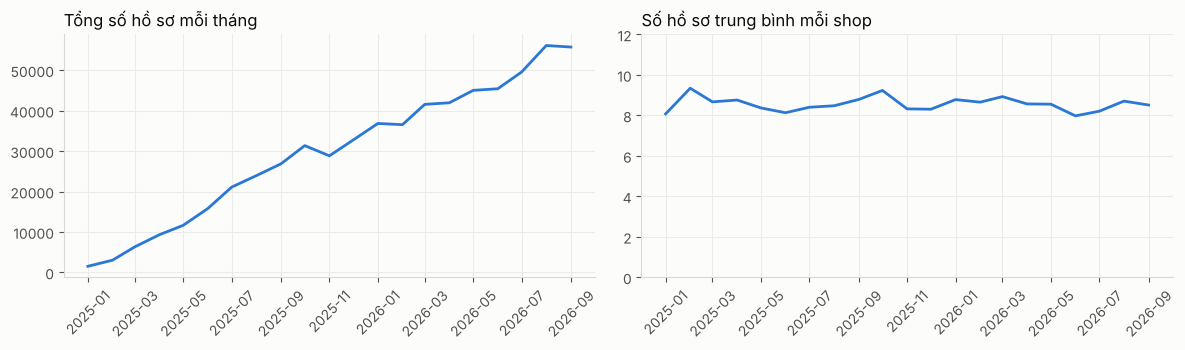

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(thang.thang, thang.ho_so, color=BLUE); ax[0].set_title('Tổng số hồ sơ mỗi tháng', loc='left', color=INK)
ax[1].plot(thang.thang, thang.ho_so_moi_shop, color=BLUE); ax[1].set_ylim(0, 12)
ax[1].set_title('Số hồ sơ trung bình mỗi shop', loc='left', color=INK)
for a in ax: a.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

Gần như toàn bộ tăng trưởng đến từ việc mở thêm shop: tổng số hồ sơ tăng khoảng 37 lần (01/2025 – 09/2026) chủ yếu vì số shop có hồ sơ tăng khoảng 35 lần, trong khi số hồ sơ mỗi shop đứng yên ở 8–9 hồ sơ mỗi tháng.

Nhưng con số trung bình mỗi shop ở trên trộn chung hai loại shop: shop vừa mở và shop đã bán từ lâu. Mỗi tháng có hàng trăm shop mới mở, nên tỷ trọng của hai loại shop thay đổi liên tục. Vì vậy mức trung bình đứng yên chưa cho biết các shop đã bán từ lâu đang bán nhiều lên, đứng yên hay ít đi. Phần tiếp theo tách hai loại shop ra để xem.

Trước hết cần một mốc để tính shop đã hoạt động được bao lâu. Bảng salesroom có cột `salesroom_start`, theo mô tả cột của Ban tổ chức là ngày shop bắt đầu hoạt động. Mọi shop đều có ngày này, kể cả shop chưa có khách nào, nên notebook dùng nó làm mốc chung.

Câu lệnh dưới đây kiểm tra mốc này bằng cách so với ngày có hồ sơ đầu tiên của shop (ngày sớm nhất một khách nộp hồ sơ tại shop): bao nhiêu shop có hồ sơ đầu tiên trước ngày bắt đầu hoạt động, shop đứng giữa phải chờ bao nhiêu ngày mới có hồ sơ đầu tiên, bao nhiêu phần trăm shop có hồ sơ đầu tiên trong vòng 30 ngày, và mức mà 1/10 số shop chậm nhất phải chờ.

In [ ]:
q('''with f as (select skp_salesroom, min(date_apply) ngay_dau from contract
   where skp_salesroom in (select skp_salesroom from salesroom) group by 1)
select (select count(*) from salesroom) so_shop_trong_bang, (select count(salesroom_start) from salesroom) so_shop_co_ngay_bat_dau,
  count(*) so_shop_co_ho_so, sum((ngay_dau < salesroom_start)::int) shop_co_ho_so_truoc_ngay_bat_dau,
  median(date_diff('day', salesroom_start, ngay_dau)) so_ngay_cho_trung_vi,
  avg((date_diff('day', salesroom_start, ngay_dau) <= 30)::int) ty_le_trong_30_ngay,
  quantile_cont(date_diff('day', salesroom_start, ngay_dau), 0.9) so_ngay_cho_cua_10pct_cham_nhat
from f join salesroom using(skp_salesroom)''')

,so_shop_trong_bang,so_shop_co_ngay_bat_dau,so_shop_co_ho_so,shop_co_ho_so_truoc_ngay_bat_dau,so_ngay_cho_trung_vi,ty_le_trong_30_ngay,so_ngay_cho_cua_10pct_cham_nhat
0,14216,14216,11405,0,13,0.718,85


- Cả 14.216 shop đều có ngày bắt đầu hoạt động. Trong 11.405 shop đã có hồ sơ, không shop nào có hồ sơ trước ngày này, nên mốc này dùng được.
- Hồ sơ đầu tiên thường đến sau ngày bắt đầu hoạt động một khoảng: shop đứng giữa chờ 13 ngày, 72% shop có hồ sơ đầu tiên trong vòng 30 ngày, và 1/10 số shop phải chờ từ 85 ngày trở lên.

Thời gian chờ khách đầu tiên cũng là một phần của việc shop bán tốt hay kém: một shop đã hoạt động 3 tháng mà chưa có khách là điều ban quản lý cần thấy. Vì vậy thời gian hoạt động của shop được đếm từ ngày bắt đầu hoạt động, không phải từ ngày có hồ sơ đầu tiên.

Câu hỏi tiếp theo: một shop thường bán được bao nhiêu trong tháng đầu tiên mở cửa, tháng thứ hai, tháng thứ ba, và về sau?

Các shop mở cửa vào những thời điểm khác nhau, nên không thể so theo tháng trên lịch. Thay vào đó, tháng của mỗi shop được đánh số theo thời gian hoạt động của riêng shop đó, gọi là **tháng hoạt động thứ 1, thứ 2, thứ 3...** Tháng hoạt động thứ 1 là tháng shop bắt đầu hoạt động. Ví dụ:
- shop X bắt đầu hoạt động ngày 15/06/2025: tháng 06/2025 là tháng hoạt động thứ 1 của shop X, tháng 07/2025 là tháng hoạt động thứ 2;
- shop Y bắt đầu hoạt động ngày 02/03/2026: tháng 03/2026 là tháng hoạt động thứ 1 của shop Y, tháng 04/2026 là tháng hoạt động thứ 2.

Như vậy tháng 06/2025 của shop X và tháng 03/2026 của shop Y được xếp chung một dòng, vì đều là tháng đầu tiên của hai shop.

Câu lệnh dưới đây tính số contract trung bình mỗi shop ở từng tháng hoạt động. Mỗi shop được tính ở mọi tháng từ lúc bắt đầu hoạt động đến 09/2026, hoặc đến tháng đóng cửa nếu shop đã đóng (cột `salesroom_end`), kể cả những tháng không ký được contract nào. Các cột kết quả:
- `thang_hoat_dong_thu`: tháng hoạt động thứ mấy. Dòng cuối gộp mọi tháng từ tháng hoạt động thứ 13 trở đi;
- `so_shop_thang`: số shop-tháng được tính ở dòng đó. Ở các dòng 1 đến 12, mỗi shop góp đúng một tháng nên con số này cũng là số shop; dòng cuối gộp nhiều tháng của cùng một shop nên lớn hơn;
- `hd_moi_shop`: số contract trung bình mỗi shop trong tháng đó;
- `ty_le_shop_ky_duoc_hd`: tỷ lệ shop ký được ít nhất một contract trong tháng đó.

In [ ]:
thang_thu = q('''with g as (select skp_salesroom,
      unnest(generate_series(date_trunc('month', salesroom_start)::date,
                             least(coalesce(date_trunc('month', salesroom_end)::date, date '2026-09-01'), date '2026-09-01'),
                             interval 1 month))::date thang,
      date_trunc('month', salesroom_start)::date thang_bat_dau
    from salesroom where salesroom_start < date '2026-10-01'),
hd as (select skp_salesroom, apply_month thang, sum(is_signed) hd from contract group by all)
select case when date_diff('month', thang_bat_dau, thang) + 1 >= 13 then '13 trở đi'
            else (date_diff('month', thang_bat_dau, thang) + 1)::varchar end thang_hoat_dong_thu,
  count(*) so_shop_thang, avg(coalesce(hd.hd, 0)) hd_moi_shop, avg((coalesce(hd.hd, 0) > 0)::int) ty_le_shop_ky_duoc_hd
from g left join hd using(skp_salesroom, thang)
group by 1 order by min(date_diff('month', thang_bat_dau, thang))''')
thang_thu

,thang_hoat_dong_thu,so_shop_thang,hd_moi_shop,ty_le_shop_ky_duoc_hd
0,1,13937,1.523,0.335
1,2,13412,3.470,0.513
2,3,12721,3.543,0.512
3,4,11871,3.478,0.503
4,5,10903,3.396,0.498
5,6,9848,3.446,0.494
6,7,8946,3.345,0.495
7,8,8227,3.230,0.486
8,9,7701,3.221,0.489
9,10,6922,3.132,0.485


- Ở tháng hoạt động thứ 1, một shop chỉ ký trung bình 1,5 contract, và chỉ 1/3 số shop ký được ít nhất một contract.
- Từ tháng hoạt động thứ 2 trở đi, mức trung bình ổn định hơn nhiều, khoảng 3,1–3,5 contract mỗi tháng, và giảm nhẹ dần theo thời gian.
- Ở mọi tháng từ tháng hoạt động thứ 2 trở đi, chỉ khoảng một nửa số shop đang hoạt động (48–51%) ký được ít nhất một contract. Nghĩa là trong một tháng bất kỳ, khoảng một nửa số shop không bán được gì.

Mức 3,1–3,5 contract ở đây thấp hơn mức 5–6 contract mỗi shop ở bảng đầu mục này, vì bảng đầu chỉ tính shop có hồ sơ trong tháng, còn bảng này tính mọi shop đang hoạt động.

Câu lệnh dưới đây xem vì sao tháng hoạt động thứ 1 thấp hơn hẳn: shop thường bắt đầu hoạt động vào ngày nào trong tháng, và trong tháng hoạt động thứ 1 shop hoạt động được bao nhiêu ngày (tính từ ngày bắt đầu đến hết tháng, cả ngày bắt đầu), bằng bao nhiêu phần của cả tháng.

In [ ]:
q('''select count(*) so_shop, median(day(salesroom_start)) ngay_bat_dau_trung_vi,
  avg(day(last_day(salesroom_start)) - day(salesroom_start) + 1) so_ngay_hoat_dong_thang_1,
  avg((day(last_day(salesroom_start)) - day(salesroom_start) + 1) / day(last_day(salesroom_start))) phan_thang_hoat_dong
from salesroom where salesroom_start < date '2026-10-01' ''')

,so_shop,ngay_bat_dau_trung_vi,so_ngay_hoat_dong_thang_1,phan_thang_hoat_dong
0,13937,16,15.806,0.518


- Shop thường bắt đầu hoạt động vào giữa tháng: shop đứng giữa bắt đầu ngày 16. Tính trung bình, trong tháng hoạt động thứ 1 shop chỉ hoạt động khoảng 15,8 ngày, tức khoảng 52% của tháng.
- Số contract của tháng hoạt động thứ 1 (1,5) chỉ bằng khoảng 44% tháng hoạt động thứ 2 (3,5), thấp hơn mức 52% này. Phần thấp hơn còn lại phù hợp với thời gian chờ khách đầu tiên ở trên: shop đứng giữa phải chờ 13 ngày mới có hồ sơ đầu tiên.

Như vậy tháng hoạt động thứ 1 thấp chủ yếu vì shop chưa hoạt động đủ tháng và còn đang chờ khách đầu tiên. Từ tháng hoạt động thứ 2 trở đi, mức bán thay đổi ít. Mỗi tháng càng có nhiều shop đang ở tháng hoạt động thứ 1 thì mức trung bình toàn mạng lưới càng bị kéo xuống.

Phần tiếp theo bỏ tháng hoạt động thứ 1 của mỗi shop ra và theo dõi chính các shop đó qua thời gian. Các shop được chia thành nhóm theo quý bắt đầu hoạt động (ví dụ nhóm 2025-Q1 gồm các shop bắt đầu hoạt động trong tháng 01, 02 hoặc 03/2025). Chia theo quý thì mỗi nhóm có vài trăm đến hơn một nghìn shop, đủ để số trung bình không dao động vì vài shop; chia theo tháng thì nhóm nhỏ hơn và bảng có quá nhiều cột.

Câu lệnh dưới đây tạo hai bảng có cùng cách đọc:
- mỗi cột là một nhóm shop, đặt tên theo quý bắt đầu hoạt động. Ví dụ cột 2025-Q2 gồm các shop bắt đầu hoạt động trong tháng 04, 05 hoặc 06/2025;
- mỗi dòng là một tháng trên lịch;
- ô trống nghĩa là tháng đó nhóm shop chưa bắt đầu hoạt động, hoặc mới ở tháng hoạt động thứ 1 (tháng này được bỏ ra như đã nói ở trên).

Trong mỗi ô:
- **bảng thứ nhất** là số contract trung bình mỗi shop của nhóm trong tháng đó, chỉ tính các shop có hồ sơ trong tháng. Ví dụ ô ở cột 2025-Q2, dòng 09/2026 là 5,2: trong tháng 09/2026, các shop bắt đầu hoạt động trong quý 2/2025 và vẫn còn có hồ sơ ký trung bình 5,2 contract mỗi shop;
- **bảng thứ hai** là số shop của nhóm có hồ sơ trong tháng đó.

Đọc từ trên xuống trong một cột để thấy cùng một nhóm shop thay đổi thế nào theo thời gian. Biểu đồ bên dưới vẽ lại hai bảng cho bốn nhóm bắt đầu hoạt động trong năm 2025, vì đây là các nhóm có nhiều tháng để theo dõi nhất.

nhóm bắt đầu,2025-Q1,2025-Q2,2025-Q3,2025-Q4,2026-Q1,2026-Q2,2026-Q3
tháng,,,,,,,
02/2025,6.1,,,,,,
03/2025,6.5,,,,,,
04/2025,5.7,,,,,,
05/2025,6.1,4.9,,,,,
06/2025,6.6,5.1,,,,,
07/2025,6.8,5.3,,,,,
08/2025,6.9,5.5,5.6,,,,
09/2025,6.9,5.6,6.0,,,,
10/2025,7.0,5.6,6.5,,,,


nhóm bắt đầu,2025-Q1,2025-Q2,2025-Q3,2025-Q4,2026-Q1,2026-Q2,2026-Q3
tháng,,,,,,,
02/2025,239,,,,,,
03/2025,474,,,,,,
04/2025,810,,,,,,
05/2025,766,375,,,,,
06/2025,731,806,,,,,
07/2025,748,"1,382",,,,,
08/2025,717,"1,336",472,,,,
09/2025,706,"1,298",828,,,,
10/2025,694,"1,270","1,129",,,,


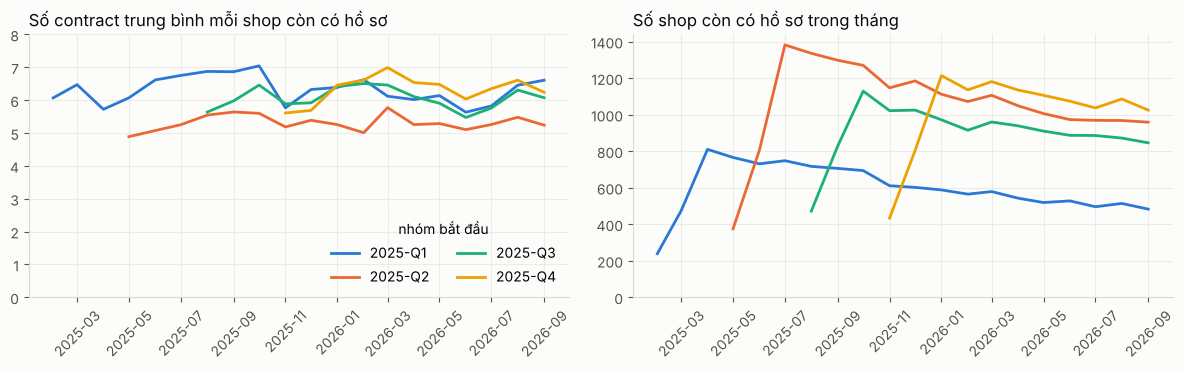

In [ ]:
nhom = q('''with sm as (select skp_salesroom, apply_month thang, sum(is_signed) hd from contract
   where skp_salesroom in (select skp_salesroom from salesroom) group by all)
select year(salesroom_start) || '-Q' || quarter(salesroom_start) nhom_bat_dau, thang, count(*) so_shop, avg(hd) hd_moi_shop
from sm join salesroom using(skp_salesroom) where thang > date_trunc('month', salesroom_start) group by all order by all''')
nhom['thang'] = pd.to_datetime(nhom.thang)
def bang(cot, so_le):
    b = nhom.pivot(index='thang', columns='nhom_bat_dau', values=cot).sort_index()
    b.index = b.index.strftime('%m/%Y'); b.index.name = 'tháng'; b.columns.name = 'nhóm bắt đầu'
    return b.apply(lambda c: c.map(lambda v: '' if pd.isna(v) else f'{v:,.{so_le}f}'))
display(bang('hd_moi_shop', 1))
display(bang('so_shop', 0))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for mau, ten in zip([BLUE, ORANGE, '#1baf7a', '#eda100'], ['2025-Q1', '2025-Q2', '2025-Q3', '2025-Q4']):
    d = nhom[nhom.nhom_bat_dau == ten]
    ax[0].plot(d.thang, d.hd_moi_shop, color=mau, label=ten)
    ax[1].plot(d.thang, d.so_shop, color=mau, label=ten)
ax[0].set_ylim(0, 8); ax[0].set_title('Số contract trung bình mỗi shop còn có hồ sơ', loc='left', color=INK)
ax[1].set_ylim(0, None); ax[1].set_title('Số shop còn có hồ sơ trong tháng', loc='left', color=INK)
for a in ax: a.tick_params(axis='x', rotation=45)
ax[0].legend(title='nhóm bắt đầu', frameon=False, loc='lower right', ncol=2)
plt.tight_layout(); plt.show()

- **Shop không bán nhiều hơn khi hoạt động lâu hơn.** Trong từng nhóm, số contract trung bình của các shop còn bán gần như đi ngang. Nhóm 2025-Q1 dao động 5,6–7,0 contract mỗi tháng từ 02/2025 đến 09/2026, và tháng cuối (6,6) gần bằng tháng đầu (6,1). Nhóm 2025-Q2 dao động 4,9–5,8, nhóm 2025-Q3 dao động 5,5–6,5, cũng không có xu hướng đi lên.
- **Mỗi nhóm mất dần số shop đang bán.** Ở 2–3 tháng đầu của mỗi nhóm, số shop tăng lên vì các shop trong cùng một quý bắt đầu hoạt động lần lượt từng tháng. Sau đó số shop giảm dần: nhóm 2025-Q1 từ 810 shop có hồ sơ (04/2025) còn 483 shop (09/2026), giảm 40%. Nhóm 2025-Q2 từ 1.382 shop (07/2025) còn 959 shop, giảm 31%. Nhóm 2025-Q3 từ 1.129 shop (10/2025) còn 846 shop, giảm 25%.

Như vậy mức trung bình mỗi shop của toàn mạng lưới đứng yên vì từ tháng hoạt động thứ 2 trở đi, shop nào còn bán cũng ở quanh một mức gần như cố định. Shop không lớn dần lên theo thời gian, và mỗi nhóm shop còn mất dần số shop đang bán. Tổng doanh số tăng chỉ vì số shop mới mở nhiều hơn số shop ngừng bán.

## 0.4. Contract của từng sản phẩm được ghi ở đâu

Câu lệnh dưới đây đếm, với mỗi sản phẩm, tổng số hồ sơ và số hồ sơ ghi tại shop có trong bảng salesroom. Phần còn lại được ghi ở các mã điểm bán không có trong bảng, chủ yếu là kênh online. Các sản phẩm: CD (mua điện thoại, điện máy trả góp), TW (mua xe máy trả góp), CL (Cash Loan, vay tiền mặt), CC (Credit Card, thẻ tín dụng), BNPL (mua trước trả sau), CW (một loại vay khác có trong dữ liệu). Dòng trống là hồ sơ không ghi sản phẩm.

In [ ]:
q('''select product san_pham, count(*) ho_so, sum((skp_salesroom in (select skp_salesroom from salesroom))::int)::int ghi_tai_shop,
  1 - ghi_tai_shop/ho_so ty_le_ngoai_bang
from contract group by 1 order by 2 desc''')

,san_pham,ho_so,ghi_tai_shop,ty_le_ngoai_bang
0,CL,1389963,24753,0.982
1,BNPL,951483,43892,0.954
2,CD,450608,450608,0
3,CC,416796,18198,0.956
4,TW,329335,73477,0.777
5,CW,188039,2046,0.989
6,NaN,49140,8413,0.829


- Gần như mọi khoản vay tiền mặt, thẻ và mua trước trả sau (CL, CC, BNPL, CW) đều ký qua kênh online: 95–99% hồ sơ của các sản phẩm này nằm ngoài bảng salesroom. Muốn biết một shop có góp phần vào các khoản này hay không, phải đi qua lead: shop tạo lead cho khách, rồi khách ký contract qua online. Đây chính là phần cross-sell (bán chéo) mà đề yêu cầu tính.
- 78% hồ sơ TW nằm ngoài bảng, nên phần TW trong bảng chỉ là một phần nhỏ của mảng xe máy. Phần giới hạn dữ liệu ở cuối notebook nói thêm về điểm này.

## 0.5. Rủi ro: khách trễ hạn ngay kỳ trả đầu

Cột `dpd_1pd` bằng 1 nghĩa là khách trễ hạn ngay kỳ trả đầu tiên. Câu lệnh dưới đây tính tỷ lệ này theo tháng ký, cho mọi contract đã ký (`ty_le_tre_toan_bo`), riêng contract ký tại shop trong bảng (`ty_le_tre_tai_shop`), riêng contract ký ở nơi khác (`ty_le_tre_noi_khac`), và chênh lệch giữa hai nhóm sau. Cột `is_risk_cohort` đánh dấu các tháng được dùng để đo rủi ro (bằng 1 với contract ký từ 03/2025 đến hết 07/2026); bảng in cả các tháng còn lại để thấy vì sao chúng bị loại.

In [ ]:
q('''with c as (select *, coalesce(skp_salesroom in (select skp_salesroom from salesroom), false) ky_tai_shop
           from contract where is_signed=1)
select sign_month thang_ky, max(is_risk_cohort) is_risk_cohort, count(*) so_hd, avg(dpd_1pd) ty_le_tre_toan_bo,
  avg(dpd_1pd) filter (where ky_tai_shop) ty_le_tre_tai_shop, avg(dpd_1pd) filter (where not ky_tai_shop) ty_le_tre_noi_khac,
  ty_le_tre_tai_shop - ty_le_tre_noi_khac chenh_lech
from c group by 1 order by 1''')

,thang_ky,is_risk_cohort,so_hd,ty_le_tre_toan_bo,ty_le_tre_tai_shop,ty_le_tre_noi_khac,chenh_lech
0,2025-01-01,0,145794,0.002,0.003,0.002,0.001
1,2025-02-01,0,111468,0.017,0.008,0.017,-0.009
2,2025-03-01,1,133258,0.071,0.100,0.070,0.030
3,2025-04-01,1,134174,0.068,0.108,0.067,0.041
4,2025-05-01,1,131129,0.068,0.103,0.066,0.038
5,2025-06-01,1,138976,0.074,0.104,0.072,0.031
6,2025-07-01,1,134905,0.074,0.114,0.069,0.045
7,2025-08-01,1,129593,0.077,0.124,0.070,0.054
8,2025-09-01,1,128273,0.073,0.114,0.067,0.047
9,2025-10-01,1,134899,0.072,0.110,0.065,0.045


- Contract ký tháng 01 và 02/2025 có tỷ lệ trễ hạn chỉ 0,2% và 1,7%, trong khi từ 03/2025 đến 07/2026, tháng nào cũng ở mức 6,8–8,8%. Mức thấp khác thường này không phản ánh rủi ro thật nên hai tháng đầu không được dùng.
- Contract ký từ 08/2026 trở đi có kỳ trả đầu tiên rơi vào khoảng một tháng sau, sát ngày cuối của dữ liệu (17/10/2026). Với các contract này, nhiều khách chưa đến hạn hoặc chưa đủ ngày để bị ghi trễ hạn: tỷ lệ của tháng 09/2026 chỉ là 4,2% và tháng 10/2026 là 0%. Tháng 08/2026 (8,3%) đã gần mức bình thường nhưng cũng bị loại để chắc chắn mọi trường hợp trễ hạn đều đã được ghi nhận.

Vì vậy rủi ro được đo trên contract ký từ 03/2025 đến hết 07/2026.

Câu lệnh dưới đây tính tỷ lệ chung cho cả giai đoạn 03/2025 – 07/2026, tách contract ký tại shop trong bảng và contract ký ở nơi khác.

In [ ]:
q('''select coalesce(skp_salesroom in (select skp_salesroom from salesroom), false) ky_tai_shop, count(*) so_hd, avg(dpd_1pd) ty_le_tre
from contract where is_risk_cohort=1 group by 1 order by 1''')

,ky_tai_shop,so_hd,ty_le_tre
0,False,1837919,0.069
1,True,342719,0.104


- Contract ký tháng 01 và 02/2026, giai đoạn quanh Tết, có tỷ lệ trễ cao nhất (8,8% và 8,5% tính trên toàn bộ contract).
- Contract ký tại shop có tỷ lệ trễ cao hơn hẳn: 10,4%, so với 6,9% ở nơi khác. Bảng theo tháng ký ở trên cho thấy điều này đúng ở cả 17 tháng từ 03/2025 đến 07/2026: tại shop 9,1–12,4%, ở nơi khác 6,4–8,0%, và cột `chenh_lech` luôn dương, từ 2,3 đến 5,4 điểm phần trăm.

Con số này cho biết vì sao không thể chỉ đẩy doanh số: nếu một shop tăng số contract bằng cách duyệt dễ hơn cho khách trả nợ kém, công ty có thể mất tiền.

## 0.6. Lead: cơ hội bán thêm cho khách cũ

Câu lệnh dưới đây xem dữ liệu lead có từ tháng nào đến tháng nào, có bao nhiêu lead, và bao nhiêu lead gắn với shop có trong bảng salesroom. Số lead được tính theo hai cách: đếm số dòng, và nhân với cột `sample_weight` (cột này không có trong mô tả của Ban tổ chức; Bước 1 mục 1.4 giải thích vì sao nhóm hiểu đây là trọng số mẫu).

In [ ]:
q('''select min(created_month) thang_dau, max(created_month) thang_cuoi,
  count(*) so_dong, count(*) filter (where skp_salesroom in (select skp_salesroom from salesroom)) / count(*) ty_le_dong_tai_shop,
  sum(sample_weight) so_lead_nhan_trong_so,
  sum(sample_weight) filter (where skp_salesroom in (select skp_salesroom from salesroom)) / sum(sample_weight) ty_le_lead_tai_shop
from leads''')

,thang_dau,thang_cuoi,so_dong,ty_le_dong_tai_shop,so_lead_nhan_trong_so,ty_le_lead_tai_shop
0,2025-12-01,2026-10-01,6130617,0.063,"43,454,657.0",0.029


Chỉ một phần rất nhỏ lead gắn với shop có trong bảng: 6,3% số dòng, hoặc 2,9% nếu nhân `sample_weight`. Lead cũng chỉ có từ 12/2025. Vì vậy phần cross-sell tính được cho shop sẽ nhỏ và chưa đủ dài để xem xu hướng.

## 0.7. Thách thức chính và vì sao ban quản lý phải quan tâm

Từ các số trên:
- Tăng trưởng đến nay gần như hoàn toàn nhờ mở thêm shop. Mỗi shop vẫn chỉ khoảng 8–9 hồ sơ mỗi tháng. Shop không bán nhiều hơn khi mở lâu hơn, và nhiều shop ngừng bán dần: trong nhóm shop bắt đầu hoạt động đầu tiên (quý 1/2025), 40% không còn hồ sơ sau khoảng một năm rưỡi, và trong một tháng bất kỳ chỉ khoảng một nửa số shop đang hoạt động ký được contract.
- Mở thêm shop thì tốn chi phí và có giới hạn. Muốn tăng tiếp, công ty phải làm cho từng shop bán được nhiều hơn.
- Nhưng một nửa số shop có bán chỉ ký được 9% tổng số contract. Ban quản lý cần biết trong số này, shop nào còn khả năng bán thêm, shop nào đã bán gần hết mức có thể vì khu vực ít khách, thiếu nhân viên hay rủi ro cao.
- Việc tăng doanh số còn phải giữ được chất lượng: khoảng 10,4% contract ký tại shop có khách trễ hạn ngay kỳ đầu.

Đây chính là câu hỏi của đề: **một shop cụ thể có thể tăng thực tế đến đâu, cái gì đang kìm nó lại, và ban quản lý nên làm gì.**

## 0.8. Mục tiêu phân tích

Mỗi mục tiêu gắn với một quyết định của Sales Management (ban quản lý bán hàng):
- **Mục tiêu 1.** Đo Current Actual (mức hiện tại) và Business-as-Usual (mức nếu để yên) của từng shop → quyết định shop nào đang đi xuống, cần can thiệp sớm.
- **Mục tiêu 2.** Tính Attainable Potential (mức đạt được nếu can thiệp hợp lý) và Addressable Market Ceiling (trần thị trường) → quyết định chỉ tiêu thực tế cho từng shop.
- **Mục tiêu 3.** Tìm nguyên nhân của opportunity gap (phần shop còn có thể tăng) → quyết định loại can thiệp: thêm nhân viên, đào tạo, giao thêm lead hay đổi cơ cấu hàng.
- **Mục tiêu 4.** Xếp ưu tiên shop → quyết định dồn nhân viên và lead vào đâu khi nguồn lực có hạn.

## 0.9. Giới hạn của dữ liệu

- **Thiếu phần lớn shop xe máy:** 78% hồ sơ TW được ghi ở điểm bán không có trong bảng salesroom, nên không biết cỡ shop, tỉnh hay kiểu làm hồ sơ của các điểm này. Kết quả cho shop TW chỉ đại diện cho phần TW có trong bảng.
- **Lead ngắn và ít gắn với shop:** lead chỉ có từ 12/2025, và chỉ 6,3% số dòng lead (2,9% nếu nhân `sample_weight`) gắn với shop trong bảng. Phần cross-sell tính được cho shop vì vậy nhỏ, và không đủ dài để xem xu hướng.
- **Kênh online không có vị trí:** contract ký online không cho biết khách ở tỉnh nào, nên khi so với dân số theo tỉnh chỉ dùng được contract ghi tại shop.